# GHSL built-up surface EDA

Mahdiyasa et al. (2026) use “distance to human activities” derived from GHSL, but do not specify the GHSL product, epoch, definition of human activity, or distance calculation. This notebook explores **2020 built-up surface** from [GHS-BUILT-S R2023A](https://developers.google.com/earth-engine/datasets/catalog/JRC_GHSL_P2023A_GHS_BUILT_S), a plausible proxy for settlements. It is **not** a confirmed reconstruction of the paper's distance layer.

The source band `built_surface` measures square metres of built-up surface in each native 100 × 100 m cell. We downloaded a rectangle extending one degree beyond the earlier Kalimantan data window, because the nearest built-up area for a boundary cell may lie outside the provinces. Run `.venv/bin/python scripts/download_ghsl_built_surface.py --project kalimantan-peat` to reproduce the source GeoTIFF under `data/interim/ghsl_built_surface/`.

For interactive EDA only, this notebook averages the 100 m source into 1 km cells, expressed as the **fraction of each 1 km cell that is built up**. Exploratory distances are measured on that 1 km grid in projected kilometres. The eventual 5 × 5 km modeling feature needs a separately documented settlement threshold, distance method, and timing policy.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
from matplotlib.ticker import FuncFormatter
import numpy as np
import pandas as pd
from pyproj import Transformer
import rasterio
from rasterio.enums import Resampling
from rasterio.features import geometry_mask
from rasterio.transform import Affine, array_bounds
from rasterio.warp import reproject
from scipy.ndimage import distance_transform_edt
import shapely
from shapely.geometry import mapping, shape
from shapely.ops import transform as transform_geom
from shapely.plotting import plot_polygon

## 1. Verify the native source grid

A value of **0** means no mapped built-up surface in that 100 m cell. The no-data sentinel is **65535** and must not be interpreted as built-up area.

In [2]:
data_dir = Path("data/interim/ghsl_built_surface")
manifest = json.loads((data_dir / "manifest.json").read_text())
source_path = data_dir / "ghsl_built_surface_2020_kalimantan_buffered.tif"
with rasterio.open(source_path) as source:
    assert source.count == 1 and source.descriptions == ("built_surface",)
    assert source.nodata == 65535
    source_crs, source_transform = source.crs, source.transform
    source_height, source_width = source.height, source.width
print("Source:", manifest["source"])
print("Native grid:", source_width, "columns ×", source_height, "rows")
print("Pixel size:", abs(source_transform.a), "m")
print("Band unit:", manifest["unit"])
print("Buffer bounds (W/S/E/N):", manifest["requested_bounds_wgs84_wsen"])

Source: GHSL GHS-BUILT-S R2023A 2020 built-up surface, via Google Earth Engine
Native grid: 13395 columns × 14211 rows
Pixel size: 100.0 m
Band unit: m2 built-up surface per 100 m grid cell
Buffer bounds (W/S/E/N): [107.5, -6.0, 120.5, 5.5]


## 2. Aggregate to a 1 km view for EDA

The source data stay at 100 m in the GeoTIFF. This derived array is smaller and faster to plot. Average built-up square metres per 100 m cell divided by 10,000 gives an approximate built-up fraction of each 1 km cell. Missing source cells remain missing.

In [3]:
factor = 10
height_1km = (source_height + factor - 1) // factor
width_1km = (source_width + factor - 1) // factor
transform_1km = source_transform * Affine.scale(factor, factor)
mean_built_m2_per_100m = np.full((height_1km, width_1km), np.nan, dtype=np.float32)
with rasterio.open(source_path) as source:
    reproject(
        source=rasterio.band(source, 1), destination=mean_built_m2_per_100m,
        src_transform=source.transform, src_crs=source.crs, src_nodata=65535,
        dst_transform=transform_1km, dst_crs=source.crs, dst_nodata=np.nan,
        resampling=Resampling.average,
    )
built_fraction = mean_built_m2_per_100m / 10000.0
print("EDA grid:", width_1km, "columns ×", height_1km, "rows")
print("Valid cells:", np.isfinite(built_fraction).sum(), "/", built_fraction.size)
print("Range:", np.nanmin(built_fraction), "to", np.nanmax(built_fraction))
assert np.nanmin(built_fraction) >= 0
assert np.nanmax(built_fraction) <= 1

EDA grid: 1340 columns × 1422 rows
Valid cells: 1420121 / 1905480
Range: 0.0 to 0.48025697


## 3. Mask to the five BIG provinces

The GHSL download includes neighboring areas for distance calculations. The provincial mask is used only for summaries and map display. Settlement candidates outside the mask remain available as distance targets.

In [4]:
with Path("data/raw/boundaries/big_kalimantan_provinces.geojson").open(encoding="utf-8") as file:
    province_geojson = json.load(file)

def keep_xy(coordinates):
    if isinstance(coordinates[0], (int, float)):
        return coordinates[:2]
    return [keep_xy(part) for part in coordinates]

converter = Transformer.from_crs("EPSG:4326", source_crs, always_xy=True)
provinces = [(feature["properties"]["WADMPR"], transform_geom(
    converter.transform,
    shape({"type": feature["geometry"]["type"],
           "coordinates": keep_xy(feature["geometry"]["coordinates"])})
)) for feature in province_geojson["features"]]
province_union = shapely.union_all([geom for _, geom in provinces])
province_mask = geometry_mask([mapping(province_union)],
                              out_shape=built_fraction.shape,
                              transform=transform_1km, invert=True, all_touched=False)
values = built_fraction[province_mask]
print(f"1 km cell centers in five provinces: {province_mask.sum():,}")
print("Missing inside provinces:", np.isnan(values).sum())
print("Exactly zero built-up fraction:", round(100 * np.mean(values == 0), 2), "%")
print("Positive built-up fraction:", round(100 * np.mean(values > 0), 2), "%")
print("Built-up fraction percentiles:", np.nanpercentile(values, [50, 90, 95, 99, 99.9]))

1 km cell centers in five provinces: 538,230
Missing inside provinces: 0
Exactly zero built-up fraction: 84.47 %
Positive built-up fraction: 15.53 %
Built-up fraction percentiles: [0.         0.00051    0.00394    0.02569142 0.16626037]


## 4. Compare settlement thresholds and exploratory distances

“Distance to human activities” requires a rule identifying what counts as a settlement. We compare **any built-up surface**, **at least 1%**, and **at least 5%** built-up area in a 1 km cell. For each rule, a distance of 0 means the cell itself meets the rule. The distance transform uses the Mollweide grid's 1 km projected spacing; its metric distortion and 1 km resolution make this an **EDA approximation**, not the final distance feature.

In [5]:
thresholds = {"any built-up": 0.0, "≥1% built-up": 0.01, "≥5% built-up": 0.05}
distance_maps = {}
rows = []
for label, threshold in thresholds.items():
    candidate = np.isfinite(built_fraction) & (built_fraction > threshold if threshold == 0 else built_fraction >= threshold)
    assert candidate.any(), f"No settlement candidates at {label}"
    distance_km = distance_transform_edt(~candidate, sampling=(1.0, 1.0)).astype(np.float32)
    distance_maps[label] = distance_km
    region_dist = distance_km[province_mask & np.isfinite(built_fraction)]
    rows.append({"rule": label, "candidate_cells_in_buffer": int(candidate.sum()),
                 "province_median_km": np.median(region_dist),
                 "province_p90_km": np.percentile(region_dist, 90),
                 "province_max_km": np.max(region_dist)})
distance_summary = pd.DataFrame(rows).set_index("rule")
distance_summary.round(2)

,candidate_cells_in_buffer,province_median_km,province_p90_km,province_max_km
rule,,,,
any built-up,155132,2.24,13.600000,67.739998
≥1% built-up,34851,8.00,31.889999,78.029999
≥5% built-up,6301,24.84,65.919998,128.949997


## 5. Map the settlement proxy and one candidate distance layer

Colors are shown only inside the provinces. The distance calculations above still consider built-up cells throughout the buffered download region.

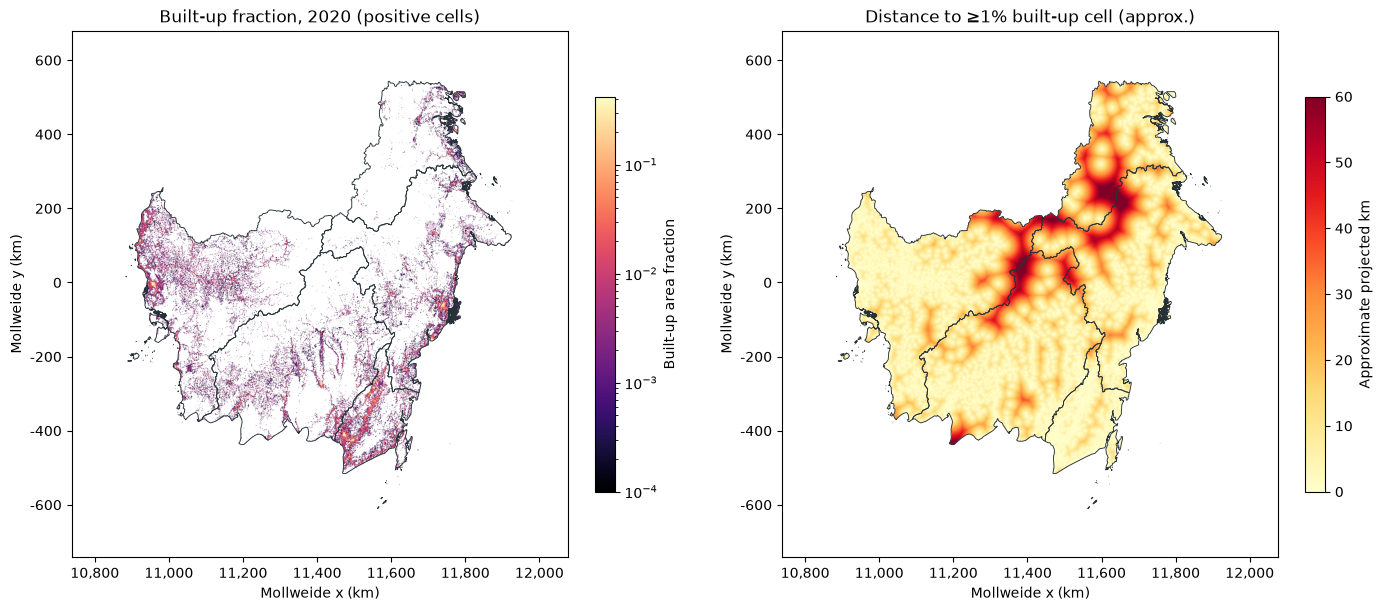

In [6]:
west, south, east, north = array_bounds(height_1km, width_1km, transform_1km)
fig, axes = plt.subplots(1, 2, figsize=(14, 6), constrained_layout=True)
positive_fraction = np.ma.masked_where(~province_mask | (built_fraction <= 0) |
                                        ~np.isfinite(built_fraction), built_fraction)
im0 = axes[0].imshow(positive_fraction, origin="upper", extent=[west, east, south, north],
                     cmap="magma", norm=LogNorm(vmin=0.0001, vmax=max(0.1, np.nanmax(values))))
distance = np.ma.masked_where(~province_mask | ~np.isfinite(built_fraction),
                              distance_maps["≥1% built-up"])
im1 = axes[1].imshow(distance, origin="upper", extent=[west, east, south, north],
                     cmap="YlOrRd", vmin=0, vmax=60)
for ax, title in zip(axes, ["Built-up fraction, 2020 (positive cells)",
                            "Distance to ≥1% built-up cell (approx.)"]):
    for _, geom in provinces:
        plot_polygon(geom.simplify(1000, preserve_topology=True), ax=ax,
                     add_points=False, facecolor="none", edgecolor="#263238", linewidth=0.65)
    ax.set(title=title, xlabel="Mollweide x (km)", ylabel="Mollweide y (km)")
    ax.set_aspect("equal", adjustable="box")
    ax.xaxis.set_major_formatter(FuncFormatter(lambda value, _: f"{value/1000:,.0f}"))
    ax.yaxis.set_major_formatter(FuncFormatter(lambda value, _: f"{value/1000:,.0f}"))
fig.colorbar(im0, ax=axes[0], shrink=0.75, label="Built-up area fraction")
fig.colorbar(im1, ax=axes[1], shrink=0.75, label="Approximate projected km")
plt.show()

## Interpretation before preprocessing

- GHSL 2020 built-up surface is a **candidate proxy** for settlement proximity, not a direct measurement of all human activity. It misses activities away from built structures.
- The paper does not tell us its GHSL layer, epoch, threshold, or distance algorithm. Do not label any exploratory distance map as an exact reproduction.
- A 2020 GHSL epoch may incorporate observations from that year and the R2023A product was released later. For a true prospective 2020 forecast, decide what layer could have been known then. For retrospective modeling, state the availability assumption clearly.
- Final preprocessing should choose a settlement definition, compute distances in an appropriate metric/geodesic system with sufficient buffer, and summarize the result on the 5 × 5 km peatland grid.